# 05 · Stress tests and extensions

Notebook 04 gave the main results. This notebook does two things a careful reader would ask for next:

**Part A. Try to break the main results** (stress tests)
1. Is the comparison with "usual" fair? (a history mismatch between training and testing)
2. What is the 2026 gain made of: less water overall, or the right places?
3. Does the region result depend on how regions and the buffer were drawn?

**Part B. Extensions promised in the proposal**

4. Gradient boosting, plain and with physics constraints
5. A two-step model (flood or not, then how much) aimed at surprise floods, with warning thresholds set by the cost of a miss
6. Uncertainty: quantile boosting ("how bad could it plausibly get") and whether its intervals hold
7. Where not to trust the model: how unusual are a season's inputs? (Gaussian mixture, Week 9)
8. A small neural network, as a check on the choice of simple models (Week 10)

Like notebook 04, it runs from `data_small/model_table.parquet` alone, in about 10 to 20 minutes. Results are reported **per held-out season or region**, never as one average, because three seasons are three single draws.

## Setup

The splits, the regions and the "usual" history are built exactly as in notebook 04. Ridge and forest reuse the settings that notebook 04 chose by cross-validation (`results/tuning_choices.csv`), so nothing here is tuned on a test fold.

In [13]:
import sys, ast, time, warnings
from pathlib import Path
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from config import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.neural_network import MLPRegressor
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import average_precision_score
from src.flood_utils import rmse, mean_bias, savefig

warnings.filterwarnings("ignore")
FAST = False
N_TREES = 60 if FAST else 300
EVENT, LABEL, BUFFER_KM = 0.05, "flooded_frac", 10
T0 = time.time()

df = pd.read_parquet(SMALL_DIR / "model_table.parquet")
FEATURES = pd.read_csv(RESULTS_DIR / "feature_dictionary.csv")["feature"].tolist()
piv = df.pivot(index="cell_id", columns="season", values=LABEL)

# regions, exactly as in notebook 04
def make_regions(cells, level="basin_l5", min_size=300):
    c = cells.groupby(level).agg(n=("cell_id", "size"), lat=("lat", "mean"), lon=("lon", "mean"))
    big = c[c.n >= min_size]
    if len(big) < 3: big = c.nlargest(3, "n")
    mapping = {}
    for b, r in c.iterrows():
        d = (big.lat - r.lat) ** 2 + ((big.lon - r.lon) * np.cos(np.radians(r.lat))) ** 2
        mapping[b] = b if b in big.index else d.idxmin()
    names = {b: f"R{i + 1}" for i, b in enumerate(big.sort_values(["lon", "lat"]).index)}
    return cells[level].map(mapping).map(names)

cells = df[df.season == YEARS[0]][["cell_id", "row", "col", "lat", "lon", "basin_l5"]].reset_index(drop=True)
cells["basin_l5"] = cells["basin_l5"].astype(int)
cells["region"] = make_regions(cells)
df = df.merge(cells[["cell_id", "region"]], on="cell_id")
REGIONS = sorted(cells.region.unique(), key=lambda r: int(r[1:]))
XY = np.c_[cells.lon * 111.32 * np.cos(np.radians(cells.lat)), cells.lat * 110.57]
tree = cKDTree(XY)

def buffer_cells(test_ids, km=BUFFER_KM):
    near = tree.query_ball_point(XY[cells.cell_id.isin(test_ids).values], r=km)
    return set(cells.cell_id.values[np.unique(np.concatenate(near))]) - set(test_ids)

def season_fold(s):
    """Training and test tables for held-out season s, with the leak-free 'usual' column."""
    a, b = [o for o in YEARS if o != s]
    tr = df[df.season.isin([a, b])].copy()
    te = df[df.season == s].copy()
    tr["usual"] = np.where(tr.season == a, tr.cell_id.map(piv[b]), tr.cell_id.map(piv[a]))   # the OTHER training season
    te["usual"] = te.cell_id.map(piv[[a, b]].mean(axis=1)).values                            # mean of both
    return tr, te, (a, b)

def region_fold(r, km=BUFFER_KM, col="region"):
    ids = set(df.loc[df[col] == r, "cell_id"])
    drop = buffer_cells(ids, km)
    return df[~df.cell_id.isin(ids | drop)], df[df.cell_id.isin(ids)]

def skill(obs, pred, ref):
    return 1 - rmse(obs, pred) ** 2 / rmse(obs, ref) ** 2

# settings chosen in notebook 04
tc = pd.read_csv(RESULTS_DIR / "tuning_choices.csv")
tc["fold"] = tc["fold"].astype(str)
def chosen(scheme, fold, model):
    return ast.literal_eval(tc[(tc.scheme == scheme) & (tc.fold == str(fold)) & (tc.model == model)]["best"].iloc[0])
def make(model, params):
    base = {"ridge": Pipeline([("scale", StandardScaler()), ("model", Ridge())]),
            "forest": RandomForestRegressor(n_estimators=N_TREES, n_jobs=-1, random_state=RANDOM_STATE)}[model]
    return clone(base).set_params(**params)

XA = FEATURES + ["usual"]
print(df.shape, "| regions:", REGIONS)

(11922, 39) | regions: ['R1', 'R2', 'R3', 'R4']


# Part A · Trying to break the main results

## Step 1 · Is the comparison with "usual" fair?

There is a subtle mismatch in notebook 04's season hold-out. When the model **trains**, each row's "usual" comes from **one** other season. When it is **tested**, "usual" is the average of **two** seasons, which is a steadier number.

Why that matters: a one-season history is noisy, so the model learns "don't trust usual too much, pull big values back toward zero". Applied to the steadier two-season history at test time, that pull-back is too strong. Part of the models' loss against usual in 2024 and 2025 could come from this mismatch, not from the features being useless.

**The fix that keeps everything leak-free:** at test time, give the model the same kind of history it trained on. Predict once with season *a* as the history and once with season *b*, then average the two predictions ("history-matched"). We also add the simplest possible model, **shrunken usual**: usual multiplied by one number *k* learned on the training seasons.

In [14]:
rowsA, predA = [], {}
for s in YEARS:
    tr, te, (a, b) = season_fold(s)
    y_tr = tr[LABEL] - tr["usual"]
    out = te[["cell_id", "season", "region", "row", "col", "lat", "lon", "usual"]].copy()
    out["obs"] = te[LABEL].values
    k = float((tr[LABEL] * tr["usual"]).sum() / (tr["usual"] ** 2).sum())
    out["shrunken usual"] = k * out["usual"]
    for m in ["ridge", "forest"]:
        est = make(m, chosen("A season", s, m)).fit(tr[XA], y_tr)
        out[m] = np.clip(te["usual"].values + est.predict(te[XA]), 0, 1)                  # as in notebook 04
        parts = []
        for h in (a, b):                                                                   # one history at a time
            x = te[XA].copy(); x["usual"] = te.cell_id.map(piv[h]).values
            parts.append(np.clip(x["usual"].values + est.predict(x), 0, 1))
        out[m + " (history-matched)"] = np.mean(parts, axis=0)
    predA[s] = out
    for c in ["shrunken usual", "ridge", "ridge (history-matched)", "forest", "forest (history-matched)"]:
        rowsA.append(dict(season=s, method=c, skill_vs_usual=skill(out.obs, out[c], out.usual)))
    print(f"season {s}: k = {k:.2f}  ({time.time() - T0:.0f} s)")
predA = pd.concat(predA.values(), ignore_index=True)
t1 = pd.DataFrame(rowsA).pivot(index="method", columns="season", values="skill_vs_usual").round(3)
t1.to_csv(RESULTS_DIR / "x1_history_matched.csv"); t1

season 2024: k = 0.76  (1 s)
season 2025: k = 0.75  (3 s)
season 2026: k = 0.90  (5 s)


season,2024,2025,2026
method,,,
forest,-0.415,-0.385,0.116
forest (history-matched),-0.365,-0.312,0.112
ridge,-0.139,-0.339,0.063
ridge (history-matched),-0.139,-0.339,0.063
shrunken usual,-0.057,-0.442,0.125


**How to read this.** `k` below 1 confirms that a one-season history is over-trusted and gets pulled back. If the history-matched rows are clearly better than the plain ones in 2024 and 2025, part of notebook 04's negative result was the mismatch, and the history-matched numbers are the fairer ones to quote. If they are still below 0, the negative result stands on firmer ground: even with a fair setup, features don't beat history in ordinary seasons.

## Step 2 · What is the 2026 gain made of?

2026 was the driest season. A model could beat "usual" there in two very different ways:
- **less water overall**: it only learned "dry year, turn everything down" (useful, but shallow), or
- **the right places**: it moved flooding to where it actually happened.

Two checks. (1) An **oracle** that cheats: usual rescaled so its average equals the true 2026 average. It knows the season total but nothing about places. If our models only match the oracle, their gain is the "less water overall" kind. (2) The **anomaly correlation**: across squares, does the predicted change from usual line up with the observed change? Zero means the model has no idea where the season differs.

In [15]:
rows2 = []
for s, g in predA.groupby("season"):
    oracle = g.usual * g.obs.mean() / g.usual.mean()
    rows2.append(dict(season=s, method="oracle: usual rescaled to the true season mean (cheats)",
                      skill_vs_usual=skill(g.obs, oracle, g.usual), anomaly_corr=np.nan, mean_pred=oracle.mean()))
    for m in ["ridge (history-matched)", "forest (history-matched)"]:
        rows2.append(dict(season=s, method=m, skill_vs_usual=skill(g.obs, g[m], g.usual),
                          anomaly_corr=np.corrcoef(g[m] - g.usual, g.obs - g.usual)[0, 1], mean_pred=g[m].mean()))
    rows2.append(dict(season=s, method="(observed mean | usual mean)", skill_vs_usual=np.nan, anomaly_corr=np.nan,
                      mean_pred=g.obs.mean()))
    rows2.append(dict(season=s, method="(usual mean)", skill_vs_usual=np.nan, anomaly_corr=np.nan, mean_pred=g.usual.mean()))
t2 = pd.DataFrame(rows2).round(3)
t2.to_csv(RESULTS_DIR / "x2_what_is_the_gain.csv", index=False); t2

,season,method,skill_vs_usual,anomaly_corr,mean_pred
0,2024,oracle: usual rescaled to the true season mean...,0.036,NaN,0.032
1,2024,ridge (history-matched),-0.139,0.172,0.041
2,2024,forest (history-matched),-0.365,0.077,0.046
3,2024,(observed mean | usual mean),NaN,NaN,0.032
4,2024,(usual mean),NaN,NaN,0.034
5,2025,oracle: usual rescaled to the true season mean...,-0.060,NaN,0.040
6,2025,ridge (history-matched),-0.339,-0.195,0.036
7,2025,forest (history-matched),-0.312,-0.177,0.029
8,2025,(observed mean | usual mean),NaN,NaN,0.040
9,2025,(usual mean),NaN,NaN,0.030


**How to read this.** Compare each model's skill with the oracle's in 2026. Model ≈ oracle, with a small anomaly correlation → the gain is mostly "a drier year means less flooding everywhere". Model > oracle, or a clearly positive anomaly correlation → the model also found *where* 2026 differed. Either answer is fine for the paper, but it must be the true one.

## Step 3 · Does the region result depend on how we drew the map?

Notebook 04 used river-basin regions and a 10 km buffer. Two checks with the same forest settings:
- **a wider buffer** (25 and 50 km): if skill drops a lot, the 10 km result was helped by nearby training squares;
- **different regions**: four groups made by k-means on location alone (Week 9: groups found by a different method are a check on the first).

In [16]:
km4 = KMeans(4, n_init=10, random_state=RANDOM_STATE).fit_predict(XY)
order = np.argsort(pd.Series(XY[:, 0]).groupby(km4).mean().values)
cells["kregion"] = pd.Series(km4).map({c: f"K{i + 1}" for i, c in enumerate(order)}).values
df = df.merge(cells[["cell_id", "kregion"]], on="cell_id")
rf_params = dict(min_samples_leaf=5, max_features=0.33)        # the setting notebook 04 chose most often for regions

rows3 = []
for label, col, km in [("basins, 10 km buffer", "region", 10), ("basins, 25 km buffer", "region", 25),
                       ("basins, 50 km buffer", "region", 50), ("k-means regions, 10 km buffer", "kregion", 10)]:
    for r in sorted(df[col].unique()):
        tr, te = region_fold(r, km, col)
        p = np.clip(make("forest", rf_params).fit(tr[FEATURES], tr[LABEL]).predict(te[FEATURES]), 0, 1)
        rows3.append(dict(setup=label, fold=r, train_squares=tr.cell_id.nunique(),
                          forest_skill_vs_constant=skill(te[LABEL], p, np.full(len(te), tr[LABEL].mean()))))
    print(label, f"done ({time.time() - T0:.0f} s)")
t3 = pd.DataFrame(rows3).round(3)
t3.to_csv(RESULTS_DIR / "x3_region_robustness.csv", index=False)
t3.pivot(index="setup", columns="fold", values="forest_skill_vs_constant")

basins, 10 km buffer done (9 s)
basins, 25 km buffer done (13 s)
basins, 50 km buffer done (17 s)
k-means regions, 10 km buffer done (21 s)


fold,K1,K2,K3,K4,R1,R2,R3,R4
setup,,,,,,,,
"basins, 10 km buffer",NaN,NaN,NaN,NaN,0.328,0.667,0.278,0.382
"basins, 25 km buffer",NaN,NaN,NaN,NaN,0.331,0.693,0.294,0.428
"basins, 50 km buffer",NaN,NaN,NaN,NaN,0.328,0.740,0.326,0.437
"k-means regions, 10 km buffer",0.406,0.263,0.451,0.431,NaN,NaN,NaN,NaN


fold,K1,K2,K3,K4,R1,R2,R3,R4
setup,,,,,,,,
"basins, 10 km buffer",NaN,NaN,NaN,NaN,0.328,0.667,0.278,0.382
"basins, 25 km buffer",NaN,NaN,NaN,NaN,0.331,0.693,0.294,0.428
"basins, 50 km buffer",NaN,NaN,NaN,NaN,0.328,0.740,0.326,0.437
"k-means regions, 10 km buffer",0.406,0.263,0.451,0.431,NaN,NaN,NaN,NaN


**How to read this.** Skill that stays positive in every fold, for every buffer and for both ways of drawing regions, means the region result is not an artefact of the map. A steady decline with buffer size tells how much nearby squares were helping.

## Step 3b · How sure is the region result, and how much better than the best simple guess?

Two questions the tables so far do not answer.

**1. Against which simple guess?** Skill in notebook 04 is measured against *one constant* (the training average). But in a mostly dry region, "never flooded" is a better simple guess than the average. A fair test compares the forest with **the best of the three simple baselines in that region** (never flooded, one constant, elevation line). The best one is picked on the test region itself, which favours the baseline, so this is the strict version.

**2. How sure?** Each region gives one number. To put a range on it, the test squares are resampled in **50 km blocks** 1,000 times (the same block bootstrap as notebook 04, Week 6). Blocks are used because neighbouring squares flood together, so they are not independent pieces of evidence. All three seasons of a square stay in the same block.

Small example of the first point: if "never flooded" has an error of 0.032 and the forest 0.028, the skill against it is 1 − (0.028 ÷ 0.032)² = 0.23, even if skill against the constant looks much bigger.

In [17]:
from sklearn.linear_model import LinearRegression

def boot_skill(g, model, ref, n_boot=1000, block=10, seed=RANDOM_STATE):
    """95% interval of skill = 1 - MSE(model) / MSE(ref), resampling 50 km blocks of squares."""
    rng = np.random.default_rng(seed)
    blk = (g.row // block).astype(str) + "_" + (g.col // block).astype(str)
    sm = ((g[model] - g.obs) ** 2).groupby(blk).sum().values
    sr = ((g[ref] - g.obs) ** 2).groupby(blk).sum().values
    idx = rng.integers(0, len(sm), size=(n_boot, len(sm)))
    return np.percentile(1 - sm[idx].sum(1) / sr[idx].sum(1), [2.5, 97.5]), len(sm)

SIMPLE = ["never", "constant", "elevation"]
rows9 = []
for r in REGIONS:
    tr, te = region_fold(r)
    g = te[["cell_id", "row", "col"]].copy()
    g["obs"] = te[LABEL].values
    g["never"] = 0.0
    g["constant"] = tr[LABEL].mean()
    g["elevation"] = np.clip(LinearRegression().fit(tr[["elev_mean"]], tr[LABEL]).predict(te[["elev_mean"]]), 0, 1)
    g["forest"] = np.clip(make("forest", chosen("B region", r, "forest")).fit(tr[FEATURES], tr[LABEL]).predict(te[FEATURES]), 0, 1)
    best = min(SIMPLE, key=lambda m: rmse(g.obs, g[m]))                 # best simple guess, picked on the test region
    (c_lo, c_hi), n_blocks = boot_skill(g, "forest", "constant")
    (b_lo, b_hi), _ = boot_skill(g, "forest", best)
    rows9.append(dict(region=r, squares=g.cell_id.nunique(), blocks=n_blocks,
                      skill_vs_constant=skill(g.obs, g.forest, g.constant), vs_constant_low=c_lo, vs_constant_high=c_hi,
                      best_simple=best, skill_vs_best_simple=skill(g.obs, g.forest, g[best]), vs_best_low=b_lo, vs_best_high=b_hi,
                      verdict="better than every simple guess" if b_lo > 0 else "no clear difference"))
t9 = pd.DataFrame(rows9).round(3)
t9.to_csv(RESULTS_DIR / "x9_region_bootstrap.csv", index=False)
t9

,region,squares,blocks,skill_vs_constant,vs_constant_low,vs_constant_high,best_simple,skill_vs_best_simple,vs_best_low,vs_best_high,verdict
0,R1,1405,31,0.285,0.255,0.310,elevation,0.257,0.223,0.281,better than every simple guess
1,R2,946,16,0.667,0.555,0.798,never,0.258,-0.032,0.376,no clear difference
2,R3,375,15,0.276,0.174,0.633,elevation,0.209,0.141,0.416,better than every simple guess
3,R4,1248,23,0.382,0.212,0.519,never,0.235,-0.528,0.424,no clear difference


**How to read this.** `skill_vs_best_simple` is the honest size of the gain: how much the forest improves on the best guess that needs no machine learning. `vs_best_low` and `vs_best_high` are the 95% range. A range that stays above 0 means the forest is better than every simple guess in that region; a range that crosses 0 means the data cannot tell. `blocks` is the number of 50 km blocks in the region: with few blocks the range is wide and should be read with care.

# Part B · Extensions

## Step 4 · Gradient boosting, plain and with physics constraints

Gradient boosting (Week 5) builds many small trees, each one correcting the errors of the ones before. `HistGradientBoostingRegressor` also accepts **monotonic constraints**: we can require that predicted flooding never goes *down* when rain goes up, and never goes *up* when the ground is higher or further from a river. That puts physical knowledge into the model, which matters most when a season lies outside the training range (2026).

Settings are chosen inside the training data with the same region-grouped cross-validation as notebook 04.

In [18]:
UP   = ["rain_early", "rain_window", "max_7d", "up_rain_window", "up_rain_early", "low_share"]
DOWN = ["rel_height", "dist_riv_1k_km", "dist_riv_10k_km"]
def mono(cols, terrain=True):
    return [1 if c in UP and (terrain or c != "low_share") else -1 if (c in DOWN and terrain) else 0 for c in cols]

GRID = {"max_leaf_nodes": [7, 15], "min_samples_leaf": [50, 200]} if not FAST else {"max_leaf_nodes": [7], "min_samples_leaf": [100]}
def fit_gb(X, y, groups, cst=None, **kw):
    gb = HistGradientBoostingRegressor(learning_rate=0.05, max_iter=200, monotonic_cst=cst, random_state=RANDOM_STATE, **kw)
    k = min(4, len(np.unique(groups)))
    return GridSearchCV(gb, GRID, cv=GroupKFold(k), scoring="neg_root_mean_squared_error").fit(X, y, groups=groups).best_estimator_

rows4, gbA = [], {}
for s in YEARS:
    tr, te, _ = season_fold(s)
    y_tr = tr[LABEL] - tr["usual"]
    g = predA[predA.season == s]
    for name, cst in [("boosting", None), ("boosting + physics", mono(XA, terrain=False))]:   # anomaly target: constrain rain only
        est = fit_gb(tr[XA], y_tr, tr["region"], cst)
        p = np.clip(te["usual"].values + est.predict(te[XA]), 0, 1)
        rows4.append(dict(scheme="A season (skill vs usual)", fold=s, method=name, skill=skill(te[LABEL], p, te["usual"])))
        if cst is None: gbA[s] = (est, p)
    for m in ["ridge", "forest"]:
        rows4.append(dict(scheme="A season (skill vs usual)", fold=s, method=m, skill=skill(g.obs, g[m], g.usual)))
for r in REGIONS:
    tr, te = region_fold(r)
    const = np.full(len(te), tr[LABEL].mean())
    for name, cst in [("boosting", None), ("boosting + physics", mono(FEATURES))]:
        p = np.clip(fit_gb(tr[FEATURES], tr[LABEL], tr["region"], cst).predict(te[FEATURES]), 0, 1)
        rows4.append(dict(scheme="B region (skill vs constant)", fold=r, method=name, skill=skill(te[LABEL], p, const)))
    for m in ["ridge", "forest"]:
        p = np.clip(make(m, chosen("B region", r, m)).fit(tr[FEATURES], tr[LABEL]).predict(te[FEATURES]), 0, 1)
        rows4.append(dict(scheme="B region (skill vs constant)", fold=r, method=m, skill=skill(te[LABEL], p, const)))
print(f"done ({time.time() - T0:.0f} s)")
t4 = pd.DataFrame(rows4).round(3)
t4.to_csv(RESULTS_DIR / "x4_boosting.csv", index=False)
for sch, g in t4.groupby("scheme"):
    print(sch); display(g.pivot(index="method", columns="fold", values="skill"))

done (113 s)
A season (skill vs usual)


fold,2024,2025,2026
method,,,
boosting,-0.260,-0.391,0.017
boosting + physics,-0.283,-0.410,0.052
forest,-0.415,-0.385,0.116
ridge,-0.139,-0.339,0.063


B region (skill vs constant)


fold,R1,R2,R3,R4
method,,,,
boosting,0.312,0.680,0.243,0.425
boosting + physics,0.337,0.677,0.260,0.434
forest,0.285,0.667,0.276,0.382
ridge,0.226,0.455,0.126,0.095


**How to read this.** If boosting is no better than the forest, the limit is the data (three seasons), not the model, and a fancier model would not help. If the physics-constrained version does at least as well as plain boosting, the constraints cost nothing and make the model safer outside its training range. That is the version to prefer.

## Step 5 · A two-step model for surprise floods

Notebook 04's weak spot: floods in squares that are normally dry. Models that predict the *amount* of flooding with squared error play safe and predict small numbers there.

A two-step model separates the questions (Week 4 classification): **step 1**, a classifier gives each square the probability that it floods (at least 5% underwater); **step 2**, how much. Here we focus on step 1, because for warnings the yes/no question is the one that matters.

We score it with average precision (the area under the precision-recall curve; random guessing scores the base rate), on all squares and on **normally-dry squares only**.

In [19]:
rows5, clfA = [], []
for s in YEARS:
    tr, te, _ = season_fold(s)
    clf = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_leaf_nodes=7, min_samples_leaf=100,
                                         random_state=RANDOM_STATE).fit(tr[XA], (tr[LABEL] >= EVENT).astype(int))
    o = te[["cell_id", "season", "usual", "elev_mean", "rel_height"]].copy()
    o["flood"] = (te[LABEL] >= EVENT).astype(int).values
    o["p_flood"] = clf.predict_proba(te[XA])[:, 1]
    o["forest amount"] = predA.loc[predA.season == s, "forest"].values
    o["boosting amount"] = gbA[s][1]
    clfA.append(o)
clfA = pd.concat(clfA, ignore_index=True)

scores = {"usual": clfA.usual, "low ground only (-rel_height)": -clfA.rel_height, "forest amount": clfA["forest amount"],
          "boosting amount": clfA["boosting amount"], "two-step: P(flood)": clfA.p_flood}
for sub_name, mask in [("all squares", clfA.usual > -1), ("normally-dry squares (usual < 1%)", clfA.usual < 0.01)]:
    for s in YEARS:
        m = mask & (clfA.season == s)
        for name, sc in scores.items():
            rows5.append(dict(subset=sub_name, season=s, method=name, AP=average_precision_score(clfA.flood[m], sc[m]),
                              base_rate=clfA.flood[m].mean()))
t5 = pd.DataFrame(rows5).round(3)
t5.to_csv(RESULTS_DIR / "x5_two_step_AP.csv", index=False)
for sub, g in t5.groupby("subset", sort=False):
    print(sub, "| base rate per season:", g.groupby("season").base_rate.first().round(3).to_dict())
    display(g.pivot(index="method", columns="season", values="AP"))

all squares | base rate per season: {2024: 0.127, 2025: 0.158, 2026: 0.108}


season,2024,2025,2026
method,,,
boosting amount,0.757,0.693,0.647
forest amount,0.771,0.727,0.670
low ground only (-rel_height),0.582,0.587,0.625
two-step: P(flood),0.774,0.742,0.593
usual,0.787,0.761,0.618


normally-dry squares (usual < 1%) | base rate per season: {2024: 0.01, 2025: 0.035, 2026: 0.039}


season,2024,2025,2026
method,,,
boosting amount,0.160,0.112,0.132
forest amount,0.134,0.128,0.204
low ground only (-rel_height),0.139,0.170,0.354
two-step: P(flood),0.123,0.159,0.117
usual,0.040,0.086,0.046


### Warning thresholds from the cost of a miss

A probability lets the user set the warning rule from consequences instead of a default. If a missed flood costs **R** times a false alarm, the cost-minimising rule is: **warn when P(flood) > 1 / (1 + R)**. With R = 1 that is 50%; with R = 3 it is 25%; with R = 10 it is 9%. This only works if the probabilities are honest, so we check first: among squares given about 30%, did about 30% flood?

In [20]:
bins = [0, 0.02, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
cal = clfA.groupby([pd.cut(clfA.p_flood, bins, include_lowest=True), "season"], observed=True).agg(
    n=("flood", "size"), predicted=("p_flood", "mean"), observed=("flood", "mean")).round(3).unstack("season")
print("Calibration: predicted probability vs share that actually flooded, per season"); display(cal)

rows = []
for R in [1, 3, 10]:
    thr = 1 / (1 + R)
    for s in YEARS:
        g = clfA[clfA.season == s]
        warn, dry = g.p_flood > thr, g.usual < 0.01
        rows.append(dict(miss_costs=f"{R}x a false alarm", warn_above=round(thr, 2), season=s,
                         floods=int(g.flood.sum()), misses=int((~warn & (g.flood == 1)).sum()),
                         false_alarms=int((warn & (g.flood == 0)).sum()),
                         surprise_floods_caught=f"{int((warn & (g.flood == 1) & dry).sum())} of {int(((g.flood == 1) & dry).sum())}"))
t5b = pd.DataFrame(rows); t5b.to_csv(RESULTS_DIR / "x5_cost_thresholds.csv", index=False); t5b

Calibration: predicted probability vs share that actually flooded, per season


n             predicted               observed         \
season          2024  2025  2026      2024   2025   2026     2024   2025   
p_flood                                                                    
(-0.001, 0.02]  2308  2539  2426     0.005  0.003  0.005    0.003  0.013   
(0.02, 0.05]     351   260   376     0.032  0.033  0.033    0.028  0.135   
(0.05, 0.1]      239   193   208     0.073  0.072  0.072    0.084  0.212   
(0.1, 0.2]       240   215   196     0.145  0.143  0.144    0.150  0.367   
(0.2, 0.4]       313   239   194     0.289  0.289  0.293    0.288  0.351   
(0.4, 0.7]       262   239   206     0.548  0.541  0.537    0.431  0.444   
(0.7, 1.0]       261   289   368     0.851  0.872  0.887    0.874  0.865   

                       
season           2026  
p_flood                
(-0.001, 0.02]  0.014  
(0.02, 0.05]    0.154  
(0.05, 0.1]     0.130  
(0.1, 0.2]      0.097  
(0.2, 0.4]      0.139  
(0.4, 0.7]      0.184  
(0.7, 1.0]      0.617

,miss_costs,warn_above,season,floods,misses,false_alarms,surprise_floods_caught
0,1x a false alarm,0.50,2024,503,186,121,1 of 30
1,1x a false alarm,0.50,2025,629,306,121,2 of 107
2,1x a false alarm,0.50,2026,430,180,244,0 of 117
3,3x a false alarm,0.25,2024,503,95,336,11 of 30
4,3x a false alarm,0.25,2025,629,213,276,16 of 107
5,3x a false alarm,0.25,2026,430,150,427,0 of 117
6,10x a false alarm,0.09,2024,503,34,654,19 of 30
7,10x a false alarm,0.09,2025,629,103,479,50 of 107
8,10x a false alarm,0.09,2026,430,118,676,6 of 117


**How to read this.** In the calibration table, `predicted` and `observed` should be close in each row. Where they aren't (likely in 2026, the unusual season), the cost rule will warn too much or too little, and the paper should say so. In the threshold table, watch how many surprise floods are caught as a miss is treated as more costly, and what that costs in false alarms.

## Step 6 · Uncertainty: how bad could it plausibly get?

A normal model gives one number per square. **Quantile regression** (uncertainty lecture) trains the same boosting model with a different loss, so it predicts a chosen percentile instead of the average. We fit the 10th, 50th and 90th percentiles of the anomaly. The 90th is the useful one for floods: *"flooding should exceed this only one time in ten"*.

An interval is only worth reporting if it holds. If the model is honest, about **80%** of test squares fall between the 10th and 90th percentile, and about 10% exceed the 90th. Most squares are dry and trivially "covered", so we also check the squares that actually flooded.

In [21]:
rows6, qA = [], []
for s in YEARS:
    tr, te, _ = season_fold(s)
    y_tr = tr[LABEL] - tr["usual"]
    q = {}
    for a in [0.1, 0.5, 0.9]:
        est = HistGradientBoostingRegressor(loss="quantile", quantile=a, learning_rate=0.05, max_iter=200,
                                            max_leaf_nodes=7, min_samples_leaf=100, random_state=RANDOM_STATE).fit(tr[XA], y_tr)
        q[a] = np.clip(te["usual"].values + est.predict(te[XA]), 0, 1)
    lo, hi = np.minimum(q[0.1], q[0.9]), np.maximum(q[0.1], q[0.9])
    obs = te[LABEL].values
    o = te[["cell_id", "season", "lat", "lon", "usual"]].copy(); o["obs"], o["q10"], o["q50"], o["q90"] = obs, lo, q[0.5], hi
    qA.append(o)
    wet = obs >= EVENT
    rows6.append(dict(season=s, inside_80pct_all=((obs >= lo) & (obs <= hi)).mean(), above_q90_all=(obs > hi).mean(),
                      inside_80pct_flooded=((obs >= lo) & (obs <= hi))[wet].mean(), above_q90_flooded=(obs > hi)[wet].mean(),
                      mean_width_flooded=(hi - lo)[wet].mean()))
qA = pd.concat(qA, ignore_index=True)
t6 = pd.DataFrame(rows6).round(3); t6.to_csv(RESULTS_DIR / "x6_quantile_coverage.csv", index=False); t6

,season,inside_80pct_all,above_q90_all,inside_80pct_flooded,above_q90_flooded,mean_width_flooded
0,2024,0.872,0.053,0.682,0.288,0.308
1,2025,0.841,0.126,0.464,0.526,0.186
2,2026,0.840,0.051,0.451,0.402,0.182


saved /home/tb3203/thailand-flood-ml/figures/fig_quantile_2026.png


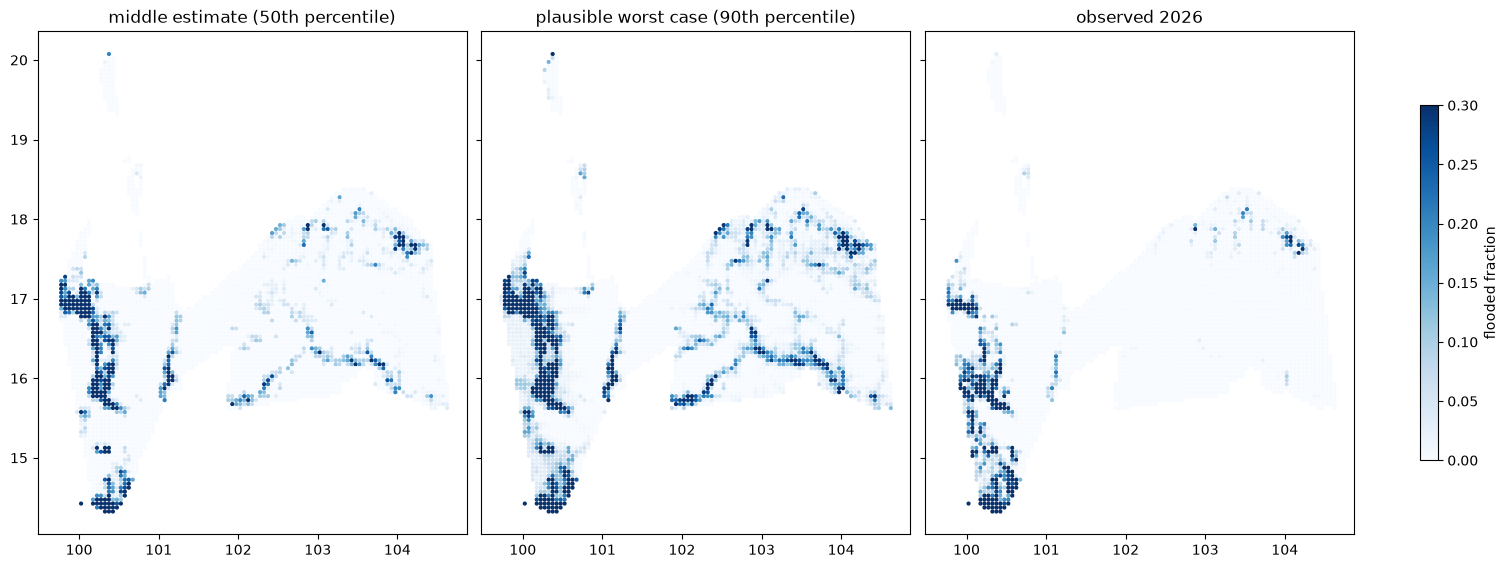

In [22]:
g = qA[qA.season == 2026]
fig, ax = plt.subplots(1, 3, figsize=(15, 6), sharey=True, layout="constrained")
for a, col, title in zip(ax, ["q50", "q90", "obs"], ["middle estimate (50th percentile)", "plausible worst case (90th percentile)", "observed 2026"]):
    sc = a.scatter(g.lon, g.lat, c=g[col], s=4, cmap="Blues", vmin=0, vmax=0.3); a.set_title(title); a.set_aspect("equal")
fig.colorbar(sc, ax=ax, shrink=0.6, label="flooded fraction")
savefig(fig, "fig_quantile_2026", FIG_DIR); plt.show()

**How to read this.** Target values: about 0.80 inside and 0.10 above. For all squares the numbers will look good, because dry squares are easy. The harder test is the **flooded** columns. Some excess there is expected, because we picked those squares *after* seeing that they flooded. But if a large share of flooded squares exceed the 90th percentile, the plausible worst case is too low exactly where it matters, and the paper must say that the stated uncertainty cannot be trusted for the big floods. Compare the seasons too: intervals learned on two seasons need not hold in a third.

## Step 7 · Where not to trust the model: how unusual are a season's inputs?

Notebook 04 found that 44% of 2026 squares had upstream rain outside the 2024 to 2025 range. That check looked at one feature at a time. A **Gaussian mixture model** (Week 9) looks at the rain features together: it learns where the training seasons' rain inputs are concentrated and gives every new square a density score, a measure of *how typical is this combination of rain numbers?* A low score means the model is being asked about weather it never saw.

Two questions: how much of each test season is "unlike training"? And are the model's errors larger there?

In [23]:
RAINF = ["rain_early", "rain_window", "rain_aug", "rain_sep", "rain_oct", "max_1d", "max_3d", "max_7d", "up_rain_window", "up_rain_early"]
rows7, dens = [], []
for s in YEARS:
    tr, te, _ = season_fold(s)
    sc_ = StandardScaler().fit(tr[RAINF])
    fits = [GaussianMixture(k, n_init=2, random_state=RANDOM_STATE).fit(sc_.transform(tr[RAINF])) for k in range(1, 7)]
    gm = min(fits, key=lambda m: m.bic(sc_.transform(tr[RAINF])))                 # number of components by BIC
    cut = np.percentile(gm.score_samples(sc_.transform(tr[RAINF])), 1)            # the 1% least typical training rows
    d = gm.score_samples(sc_.transform(te[RAINF]))
    o = pd.DataFrame({"season": s, "unlike_training": d < cut, "obs": te[LABEL].values, "usual": te["usual"].values,
                      "boosting": gbA[s][1]})
    dens.append(o)
    rows7.append(dict(season=s, components=gm.n_components, share_unlike_training=(d < cut).mean()))
dens = pd.concat(dens, ignore_index=True)
t7 = pd.DataFrame(rows7).round(3)
err = dens.groupby(["season", "unlike_training"]).apply(lambda g: pd.Series({
    "squares": len(g), "RMSE_usual": rmse(g.obs, g.usual), "RMSE_boosting": rmse(g.obs, g.boosting),
    "bias_boosting": mean_bias(g.obs, g.boosting)})).round(4)
t7.to_csv(RESULTS_DIR / "x7_unusual_inputs.csv", index=False); err.to_csv(RESULTS_DIR / "x7_error_by_unusualness.csv")
display(t7); err

,season,components,share_unlike_training
0,2024,6,0.624
1,2025,6,0.373
2,2026,5,0.202


squares  RMSE_usual  RMSE_boosting  bias_boosting
season unlike_training                                                   
2024   False             1494.0      0.0473         0.0468         0.0103
       True              2480.0      0.0517         0.0613         0.0076
2025   False             2493.0      0.0611         0.0704        -0.0084
       True              1481.0      0.0416         0.0529        -0.0015
2026   False             3171.0      0.0628         0.0653         0.0221
       True               803.0      0.0988         0.0899        -0.0240

**How to read this.** By construction, about 1% of a season that resembles training would be flagged. A much larger share means the season's weather was genuinely new to the model. If errors are larger on the flagged squares, the density score works as a "do not trust this prediction" flag that needs no flood observations at all. That is a practical safeguard to recommend in the paper.

## Step 8 · A small neural network, as a check on the model choice

The paper argues that with three seasons, simple models are the right tools. Rather than only argue it, we test it with a small network set up the way the Week 10 checklist says: inputs scaled inside a pipeline, two hidden layers (64 and 32 neurons), Adam, early stopping, and five random starts, because a network's result depends on where training begins.

In [24]:
seeds = range(2 if FAST else 5)
def mlp(seed):
    return Pipeline([("scale", StandardScaler()),
                     ("model", MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True,
                                            max_iter=300, random_state=seed))])
rows8 = []
for s in YEARS:
    tr, te, _ = season_fold(s)
    sk = [skill(te[LABEL], np.clip(te["usual"].values + mlp(i).fit(tr[XA], tr[LABEL] - tr["usual"]).predict(te[XA]), 0, 1), te["usual"]) for i in seeds]
    rows8.append(dict(scheme="A season (skill vs usual)", fold=s, network_min=min(sk), network_max=max(sk)))
for r in REGIONS:
    tr, te = region_fold(r)
    const = np.full(len(te), tr[LABEL].mean())
    sk = [skill(te[LABEL], np.clip(mlp(i).fit(tr[FEATURES], tr[LABEL]).predict(te[FEATURES]), 0, 1), const) for i in seeds]
    rows8.append(dict(scheme="B region (skill vs constant)", fold=r, network_min=min(sk), network_max=max(sk)))
t8 = pd.DataFrame(rows8)
best_simple = t4[t4.method.isin(["ridge", "forest"])].groupby(["scheme", "fold"]).skill.max().rename("best_of_ridge_forest")
t8["fold"] = t8["fold"].astype(str)
bs = best_simple.reset_index(); bs["fold"] = bs["fold"].astype(str)
t8 = t8.merge(bs, on=["scheme", "fold"]).round(3)
t8.to_csv(RESULTS_DIR / "x8_small_network.csv", index=False); t8

,scheme,fold,network_min,network_max,best_of_ridge_forest
0,A season (skill vs usual),2024,-5.874,-1.953,-0.139
1,A season (skill vs usual),2025,-1.576,-1.256,-0.339
2,A season (skill vs usual),2026,-0.472,-0.045,0.116
3,B region (skill vs constant),R1,0.011,0.331,0.285
4,B region (skill vs constant),R2,-0.077,0.274,0.667
5,B region (skill vs constant),R3,-0.645,0.288,0.276
6,B region (skill vs constant),R4,-1.465,-0.422,0.382


**How to read this.** The gap between `network_min` and `network_max` is the luck of the random start. If the network's range sits at or below the simpler models, and it moves a lot between starts, the choice of ridge and forest is supported by evidence. (The network's early stopping uses a random slice of the training rows, which favours it slightly, so this comparison is if anything generous to the network.)

## Summary

Every table above is saved in `results/` with an `x` prefix. What each step decides for the paper:

| step | decides |
|---|---|
| 1 | which season-hold-out numbers are the fair ones to quote |
| 2 | how to describe the 2026 gain: less water overall, or the right places |
| 3 | whether the region result survives a different map and wider buffers |
| 3b | how big the region gain is against the best simple guess, and how sure |
| 4 | whether a stronger model helps, and whether physics constraints cost anything |
| 5 | whether surprise floods can be flagged, and what a cost-based warning rule would do |
| 6 | whether the stated uncertainty holds, especially for flooded squares |
| 7 | a flag for predictions made on weather the model never saw |
| 8 | evidence for preferring simple models |

```bash
cd ~/thailand-flood-ml
git add -A
git commit -m "Notebook 05: stress tests and extensions"
git push
```

In [25]:
print(f"Total run time: {(time.time() - T0) / 60:.1f} min")

Total run time: 3.8 min
